# #33 Token fertility per encoding

Same Sanskrit words written in Devanagari, IAST, SLP1 and HK. How many tokens does each tokenizer spend per word?
Part of #19. Hand-in goes on the issue: one plot, 2-3 example splits, 3 sentences.

In [8]:
import re

import pandas as pd
from indic_transliteration import sanscript
from transformers import AutoTokenizer

ENCODINGS = {
    "Devanagari": sanscript.DEVANAGARI,
    "IAST": sanscript.IAST,
    "SLP1": sanscript.SLP1,
    "HK": sanscript.HK,
}
TOKENIZERS = {
    "gpt2": "gpt2",
    "qwen2.5": "Qwen/Qwen2.5-0.5B",
    "byt5": "google/byt5-small",
}

## Words

Bhagavad Gita chapter 2, Devanagari text from the [gita/gita](https://github.com/gita/gita) dataset (Unlicense; pinned to a commit),
downloaded to `data/raw/` (gitignored). We take the first 200 distinct whitespace-split strings in verse order.
These are sandhi-fused strings, not lexical words. One chapter of one text is a narrow sample, so say so in the write-up.

The source breaks verses into lines that sometimes split a word across a line boundary (e.g. `कदाचि` / `न्नायं`, which is `कदाचिन्नायं`).
We drop the last string of any line that does not end in a danda, and the first string of the next line, rather than guess.

In [9]:
import json
import urllib.request

from sandhi_probe import paths

GITA_URL = "https://raw.githubusercontent.com/gita/gita/c6fce39595445768876ddbb8d1268a9c935e1d2b/data/verse.json"
GITA_PATH = paths.RAW_DIR / "gita_verse.json"
N_WORDS = 200

if not GITA_PATH.exists():
    urllib.request.urlretrieve(GITA_URL, GITA_PATH)
chapter2 = [v for v in json.loads(GITA_PATH.read_text()) if v["chapter_number"] == 2]


def verse_words(text: str) -> list[str]:
    """Words of one verse, minus speaker lines, verse numbers, dandas and line-split fragments."""
    out: list[str] = []
    skip_next_first = False
    for line in (ln.strip() for ln in text.split("\n") if ln.strip()):
        if line.endswith("वाच"):  # "... उवाच" speaker line
            continue
        complete = bool(re.search(r"[।॥]\s*(\d+\.\d+)?\s*[।॥]*$", line))
        toks = [t for t in re.split(r"[\s।॥]+", line) if re.fullmatch(r"[\u0900-\u097F]+", t)]
        if skip_next_first and toks:
            toks = toks[1:]
        skip_next_first = not complete
        out += toks[:-1] if not complete else toks
    return out


# dedupe, keeping first-seen order
words = list(dict.fromkeys(w for v in chapter2 for w in verse_words(v["text"])))[:N_WORDS]
len(words)

200

## Transliterate

In [10]:
forms = pd.DataFrame(
    {
        name: [sanscript.transliterate(w, sanscript.DEVANAGARI, scheme) for w in words]
        for name, scheme in ENCODINGS.items()
    }
)
forms.head()

,Devanagari,IAST,SLP1,HK
0,तं,taṃ,taM,taM
1,तथा,tathā,taTA,tathA
2,कृपयाऽविष्टमश्रुपूर्णाकुलेक्षणम्,kṛpayā'viṣṭamaśrupūrṇākulekṣaṇam,kfpayA'vizwamaSrupUrRAkulekzaRam,kRpayA'viSTamazrupUrNAkulekSaNam
3,विषीदन्तमिदं,viṣīdantamidaṃ,vizIdantamidaM,viSIdantamidaM
4,वाक्यमुवाच,vākyamuvāca,vAkyamuvAca,vAkyamuvAca


## Tokenize

In [11]:
tokenizers = {name: AutoTokenizer.from_pretrained(path) for name, path in TOKENIZERS.items()}


def n_tokens(tok, text: str) -> int:
    return len(tok(text, add_special_tokens=False).input_ids)


counts = pd.DataFrame(
    [
        {"tokenizer": t, "encoding": e, "word": w, "tokens": n_tokens(tok, w)}
        for t, tok in tokenizers.items()
        for e in ENCODINGS
        for w in forms[e]
    ]
)
counts.groupby(["tokenizer", "encoding"]).tokens.mean().unstack()

encoding,Devanagari,HK,IAST,SLP1
tokenizer,,,,
byt5,24.435,9.100,11.295,8.745
gpt2,15.730,4.770,6.135,4.745
qwen2.5,8.410,4.625,5.145,4.580


## Plot: mean tokens per word

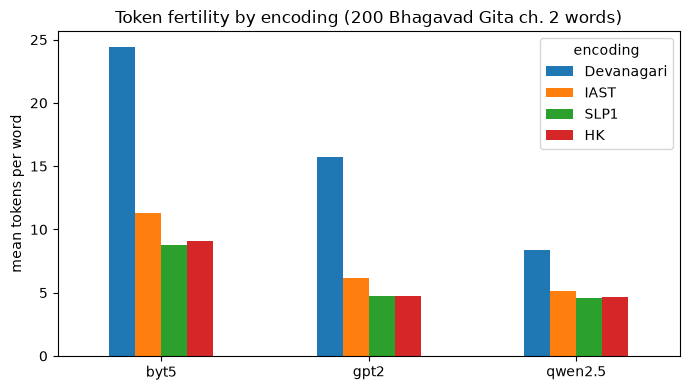

In [12]:
import matplotlib.pyplot as plt

mean_tokens = counts.groupby(["tokenizer", "encoding"]).tokens.mean().unstack()[list(ENCODINGS)]
ax = mean_tokens.plot.bar(rot=0, figsize=(7, 4))
ax.set_ylabel("mean tokens per word")
ax.set_xlabel("")
ax.set_title(f"Token fertility by encoding ({len(words)} Bhagavad Gita ch. 2 words)")
ax.legend(title="encoding")
plt.tight_layout()
plt.savefig(paths.INTERIM_DIR / "33-token-fertility.png", dpi=200)  # gitignored
plt.show()

## Supporting table: tokens per character and partial characters

`tokens_per_char` is tokens divided by the length of the word in that encoding, in characters (near 1 means cutting at almost every character).
`partial_char_share` is the share of tokens that decode to `�` (or to nothing, for ByT5) on their own, i.e. a fragment of a UTF-8 character. Both are pooled over all words.
These describe how the tokenizer cuts. They say nothing about whether the cuts fall on sandhi boundaries.

In [13]:
rows = []
for t, tok in tokenizers.items():
    for e in ENCODINGS:
        for w in forms[e]:
            ids = tok(w, add_special_tokens=False).input_ids
            decoded = [tok.decode([i]) for i in ids]
            # ByT5 decodes a lone partial byte to "", the others to "\ufffd"
            partial = sum("\ufffd" in d or d == "" for d in decoded)
            rows.append(
                {
                    "tokenizer": t,
                    "encoding": e,
                    "chars": len(w),
                    "tokens": len(ids),
                    "partial": partial,
                }
            )

support = pd.DataFrame(rows).groupby(["tokenizer", "encoding"]).sum()
support["tokens_per_char"] = support.tokens / support.chars
support["partial_char_share"] = support.partial / support.tokens
support[["tokens_per_char", "partial_char_share"]].round(2).unstack().reindex(
    columns=list(ENCODINGS), level="encoding"
)

tokens_per_char                   partial_char_share                
encoding       Devanagari  IAST  SLP1    HK         Devanagari  IAST SLP1   HK
tokenizer                                                                     
byt5                 3.00  1.24  1.00  1.00               1.00  0.33  0.0  0.0
gpt2                 1.93  0.67  0.54  0.52               0.96  0.27  0.0  0.0
qwen2.5              1.03  0.57  0.52  0.51               0.51  0.00  0.0  0.0

## Example splits

Three words by Devanagari length: the longest, the median and a short one. Each piece is decoded on its own, so `�` marks a token
that is only part of a UTF-8 character (byte-level fallback). ByT5 is left out because its tokens are just bytes.

In [14]:
ordered = sorted(words, key=len)
examples = [ordered[-1], ordered[len(ordered) // 2], ordered[0]]

for w in examples:
    print(f"=== {w}")
    for e, scheme in ENCODINGS.items():
        form = sanscript.transliterate(w, sanscript.DEVANAGARI, scheme)
        for t in ("gpt2", "qwen2.5"):
            tok = tokenizers[t]
            pieces = [tok.decode([i]) for i in tok(form, add_special_tokens=False).input_ids]
            print(f"{e:<11}{t:<8}{len(pieces):>3}  {' | '.join(pieces)}")

=== अव्यक्तोऽयमचिन्त्योऽयमविकार्योऽयमुच्यते
Devanagari gpt2     77  � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | ा | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | � | �
Devanagari qwen2.5  42  अ | व | ्� | � | क | ्� | � | ो | � | � | य | म | च | ि� | � | ्� | � | ्� | � | ो | � | � | य | म | व | ि� | � | ा� | � | ्� | � | ो | � | � | य | म | ु | च | ्� | � | त | े
IAST       gpt2     22  avy | ak | to | ' | y | amac | int | yo | ' | y | am | av | ik | ā | ry | o | ' | y | am | u | cy | ate
IAST       qwen2.5  18  avy | ak | to | 'y | amac | int | yo | 'y | am | av | ik | ā | ryo | 'y | am | uc | y | ate
SLP1       gpt2     22  avy | ak | to | ' | y | amac | int | yo | ' | y | am | av | ik | A | ry | o | ' | y | am | u | cy | ate
SLP1       qwen2.5  18  avy | ak | to | 'y | amac | int

## conclusions

- On 200 words from Gita chapter 2, Devanagari costs **1.8-3.3x as many** tokens as SLP1 on every tokenizer (GPT-2 15.7 vs 4.7, Qwen 8.4 vs 4.6, ByT5 24.4 vs 8.7). 96% of GPT-2's and 51% of Qwen's Devanagari tokens are **fragments of a character**, so a token boundary in Devanagari often falls inside a letter and says little about sandhi.
- The encoding changes how tokenizers compare: Qwen needs about half as many tokens as GPT-2 in Devanagari but is almost identical to it in HK (4.6 vs 4.8). So results reported in one encoding alone can hide differences between tokenizers.
- Overall this favors an ASCII one-character-per-sound encoding (SLP1 or HK, which behave alike here) as the canonical form for measuring boundaries, with results also reported in Devanagari since real models are used on it, pending the corpus encodings (#32) and round-trip losslessness (#34)

Caveats: 
- this doesn't say anything yet about whether cuts fall on sandhi boundaries
- As mentioned earlier, in practice, LLMs need to handle Devanagari far more often instead of SLP1 or HK
